# Shift decomposition: how much is appearance, concept, and label shift worth?

**Question.** Test-time shifts are not only noise: there are domain/style shifts and label shifts too. On each dataset, how much
accuracy is available from fixing **(A)** a class-independent domain offset in CLIP's embedding ("appearance"), **(Γ)** a
class-specific domain offset ("concept"), and **(L)** the per-domain class frequencies ("label shift")? And is any of these larger than Ramen's own gain?

**Hypothesis / predictions (pre-registered in `PREREGISTRATION.md`, written before any number).** ImageNet-C: A dominates.
DomainNet: Γ dominates (largest in sketch / quickdraw). ImageNet-R/A/Sketch: L dominates. EuroSAT: φ_A = φ_Γ = 0 exactly (bug check).

**Why this test.** Oracle ceilings on cached features: if a fix that is *given* the true labels/domains cannot beat Ramen, no label-free
version of it can, so the direction can be dropped before building a method. Offline, CPU only, minutes per dataset.

**Every cell below is an ORACLE** (uses true labels and/or true domain ids). None is a method.

| cell | prototypes | features | prior | needs |
|---|---|---|---|---|
| `txt_` | text $w_c$ (zero-shot) | $z$ | uniform | nothing |
| `txt_A` | text | $\mathrm{norm}(z-\hat\alpha_d)$ | uniform | labels + domains (α from the class-adjusted fit) |
| `txt_Ad` | text | $\mathrm{norm}(z-(\bar z_d-\bar z))$ | uniform | domains only |
| `txt_L`, `txt_AL`, `txt_AdL` | as above | as above | true $\pi_{c\mid d}$ | + labels |
| `img_` (P0) | pooled image class means $\hat\mu+\hat\beta_c$ | $z$ | uniform | labels |
| `img_A`, `img_G`, `img_AG` | $+\,\tilde\gamma_{c,d}$ if Γ | $z-\hat\alpha_d$ if A | uniform | labels + domains |
| `img_*L` | as above | as above | true $\pi_{c\mid d}$ | labels + domains |
| `img_G_n0`, `img_AG_n0` | unshrunk $\hat\gamma$ | | | robustness |
| `rnd_A`, `rnd_G`, `rnd_AG` | fitted with **random** domain labels | | | control (should ≈ P0) |
| `cf_*` | fitted on the other half of the photos/images (2-fold cross-fit) | | | estimation-noise check |

**Data.** Seed 0 cached CLIP features (`results/<ds>_..._s0_NoAdapt_feats.npy`, fp16), labels, domains; Ramen's cached seed-0 predictions.
ImageNet-C 5K (75,000 images, 15 corruptions, ViT-B/16), DomainNet (596,006, 6 domains, ViT-B/32), ImageNet-R/A/Sketch
(88,389, 3 domains, 1,000-class head, ViT-B/16), EuroSAT (27,000, 1 domain, ViT-B/16).
**Seeds.** A seed only changes the stream order; these oracles do not depend on order, so one run covers every seed. Uncertainty comes from a
cluster bootstrap over images (cluster = photo on ImageNet-C), B = 1000, estimates held fixed; estimation noise is checked by the cross-fit.

**How produced.** `python run_shift_decomposition.py <dataset>` (CPU, 16 threads), cached in `results/<dataset>_s0.{npz,pkl}`.
**What counts as a result.** Pre-registered rules: a component *dominates* if its Shapley value is ≥ 50% of the total (image world) with a CI
excluding 0; the domain-aware direction is *alive* on a dataset iff φ_A + φ_Γ (image world) > Ramen's gain over NoAdapt.
All accuracies are **domain-averaged** (mean of per-domain accuracies).

**Sections.** 1 Setup · 2 Data · 3 Sanity checks · 4 Geometry (ANOVA) · 5 Oracle cells · 6 Shapley attribution · 7 Per domain ·
8 Robustness & controls · 9 Decision · 10 Interpretation · 11 Glossary


## Method (mathematical formulation)

**Notation.** Image $i$ has frozen CLIP feature $z_i\in\mathbb S^{D-1}$ (the NoAdapt feature of Ramen's notation, $\theta_0$), true label
$y_i$ (**oracle**), domain $d_i$ (**oracle**), leave-out group $g(i)$ (the photo on ImageNet-C, else the image). $w_c$ = normalised text
embedding. Zero-shot (= NoAdapt): $\hat y_i=\arg\max_c z_i^\top w_c$. Ramen classifies with its adapted feature $\tilde z_i$ (`references/ramen.md`).

**Embedding model** (unbalanced two-way MANOVA, weighted least squares on cell sums; `anova.AdditiveFit`):
$$z_i=\mu+\alpha_{d_i}+\beta_{y_i}+\gamma_{y_i,d_i}+\varepsilon_i,\qquad \textstyle\sum_d n_d\alpha_d=0,\ \sum_c n_c\beta_c=0 .$$
$(\mu,\alpha,\beta)$ = least-squares additive fit (backfitting), $\gamma_{c,d}$ = cell mean − additive fit. $\alpha_d$: appearance, $\gamma_{c,d}$: concept, $\pi_{c\mid d}$: label shift.

**Part A (geometry).** $SS_A=\sum_d n_d\lVert\hat\alpha_d\rVert^2$, $SS_B=\sum_c n_c\lVert\hat\beta_c\rVert^2$, $SS_\Gamma=\sum_{c,d}n_{c,d}\lVert\hat\gamma_{c,d}\rVert^2$,
$SS_W=\sum_i\lVert z_i-\hat M_{y_i,d_i}\rVert^2$; per-dimension $\sigma^2=SS_W/(D(N-\#\text{cells}))$; debiased $SS_X^*=SS_X-\mathrm{df}_X D\sigma^2$ with
$\mathrm{df}_A=|\mathcal D|-1$, $\mathrm{df}_B=C-1$, $\mathrm{df}_\Gamma=\#\text{cells}-C-|\mathcal D|+1$; $F_X=SS_X/(D\,\mathrm{df}_X\sigma^2)$.

**Part B (oracle classifiers; `oracles.py`).** Image world, $S\subseteq\{A,\Gamma,L\}$:
$$\text{score}_c(z_i)=\kappa_S\Big(\tilde z_i^\top m_{c,d_i}-\tfrac12\lVert m_{c,d_i}\rVert^2\Big)+\mathbb 1[L\in S]\log\big(C\,\hat\pi_{c\mid d_i}\big),\quad
\tilde z_i=z_i-\mathbb 1[A\in S]\hat\alpha_{d_i},\quad m_{c,d}=\hat\mu+\hat\beta_c+\mathbb 1[\Gamma\in S]\tilde\gamma_{c,d}.$$
(the isotropic-Gaussian Bayes classifier = nearest class mean). With both A and Γ, $\lVert\tilde z_i-m_{c,d}\rVert=\lVert z_i-\hat M_{c,d}\rVert$ exactly.
Text world: $\text{score}_c=\tau\,z_i'^\top w_c+\mathbb 1[L]\log(C\hat\pi_{c\mid d_i})$, $z_i'=z_i$ or $\mathrm{norm}(z_i-\hat\alpha_{d_i})$.

**Honesty rules.** (1) Leave-one-out: image $i$'s true-class prototype $\hat\beta_{y_i}$, $\hat\gamma_{y_i,d_i}$ is recomputed without all of
$g(i)$ (closed-form downdate, $\hat\mu,\hat\alpha$ fixed); prior $\hat\pi^{(-i)}_{c\mid d}=(n_{c,d}-\mathbb 1[y_i=c]+1)/(n_d-1+C)$.
(2) Shrinkage $\tilde\gamma_{c,d}=\frac{n_{c,d}}{n_{c,d}+n_0}\hat\gamma_{c,d}$, $n_0=\sigma^2/\hat\tau^2$, $\hat\tau^2=(SS_\Gamma/D-\mathrm{df}_\Gamma\sigma^2)/N$ (method of moments).
(3) $\kappa_S,\tau$ by NLL (temperature scaling) on 20,000 images per prototype configuration, before adding $L$.

**Attribution.** Shapley value over the $2^3$ cells, $\phi_k=\sum_{S\subseteq N\setminus k}\frac{|S|!(n-|S|-1)!}{n!}[\mathrm{Acc}(S\cup k)-\mathrm{Acc}(S)]$,
$\sum_k\phi_k=\mathrm{Acc}(N)-\mathrm{Acc}(\varnothing)$. Text world: over $\{A,L\}$. Text-prototype gap $=\mathrm{Acc}(P0)-\mathrm{Acc}(T)$.

| symbol | meaning | code | value |
|---|---|---|---|
| $\hat\alpha,\hat\beta,\hat\gamma$ | effects | `AdditiveFit.alpha/beta/gamma` | fitted |
| $n_0$ | shrinkage pseudo-count | `AdditiveFit.n0` | per dataset (table in §4) |
| $\kappa_S,\tau$ | temperatures | `Evaluator.fit_temperature` | `meta['kappa']` |
| $g(i)$ | leave-out group | `ShiftData.group` | photo (ImageNet-C), image |
| B | bootstrap replicates | `ClusterBootstrap` | 1000 |


## 1. Setup

In [1]:
import sys, warnings
warnings.filterwarnings('ignore')
sys.path.insert(0, '.')
import numpy as np, pandas as pd
pd.set_option('display.precision', 2); pd.set_option('display.width', 200)
from experiment import ShiftDecomposition
from analysis import Summary, overview
from data import LABEL
import plots
DATASETS = ['ImageNetC5K', 'DomainNet', 'ImageNetVariants', 'EuroSAT']
S = {ds: Summary(ShiftDecomposition(ds).load()) for ds in DATASETS}

## 2. The data the code ran on
Images, classes present and median images per class in each domain; zero-shot errors as counts and %.

In [2]:
rows = []
for ds, s in S.items():
    t = s.e.meta['describe'].copy(); t.insert(0, 'dataset', LABEL[ds])
    t['zero_shot_errors'] = [f'{e:,} of {n:,} ({e / n:.1%})' for e, n in zip(t.zero_shot_errors, t.images)]
    rows.append(t)
pd.concat(rows).reset_index(drop=True)

,dataset,domain,images,classes_present,median_per_class,zero_shot_errors
0,ImageNet-C 5K,gaussian_noise,5000,997,5.0,"4,250 of 5,000 (85.0%)"
1,ImageNet-C 5K,shot_noise,5000,997,5.0,"4,156 of 5,000 (83.1%)"
2,ImageNet-C 5K,impulse_noise,5000,997,5.0,"4,232 of 5,000 (84.6%)"
3,ImageNet-C 5K,defocus_blur,5000,997,5.0,"3,716 of 5,000 (74.3%)"
4,ImageNet-C 5K,glass_blur,5000,997,5.0,"4,155 of 5,000 (83.1%)"
5,ImageNet-C 5K,motion_blur,5000,997,5.0,"3,659 of 5,000 (73.2%)"
6,ImageNet-C 5K,zoom_blur,5000,997,5.0,"3,771 of 5,000 (75.4%)"
7,ImageNet-C 5K,snow,5000,997,5.0,"3,300 of 5,000 (66.0%)"
8,ImageNet-C 5K,frost,5000,997,5.0,"3,349 of 5,000 (67.0%)"
9,ImageNet-C 5K,fog,5000,997,5.0,"3,041 of 5,000 (60.8%)"


## 3. Sanity checks
`txt_` must reproduce the cached NoAdapt predictions on ≥ 99.4% of images (fp16 features); on EuroSAT (one domain) every A / Γ cell must equal P0 on 100.00%.

In [3]:
pd.DataFrame({LABEL[ds]: s.e.meta['sanity'] for ds, s in S.items()}).T

,txt_vs_cached_noadapt_pct,txt_vs_cached_noadapt_n_diff,img_A_eq_img__pct,img_G_eq_img__pct,img_AG_eq_img__pct,img_AL_eq_img_L_pct,img_GL_eq_img_L_pct,img_AGL_eq_img_L_pct
ImageNet-C 5K,99.43,426.0,NaN,NaN,NaN,NaN,NaN,NaN
DomainNet,99.70,1811.0,NaN,NaN,NaN,NaN,NaN,NaN
ImageNet-R/A/Sketch,99.68,282.0,NaN,NaN,NaN,NaN,NaN,NaN
EuroSAT,99.58,113.0,100.0,100.0,100.0,100.0,100.0,100.0


## 4. Geometry: where the embedding variance sits (Part A)

In [4]:
rows = []
for ds, s in S.items():
    for r in s.e.meta['anova']:
        rows.append(dict(dataset=LABEL[ds], **r))
    rel = s.e.meta['reliability']
    print(f"{LABEL[ds]:22s} n0 = {s.e.meta['n0']:.3g}   gamma split-half r = {rel['r']:.3f}, Spearman-Brown {rel['r_full']:.3f} "
          f"({rel['cells']:,} cells)")
pd.DataFrame(rows)

ImageNet-C 5K          n0 = 31.4   gamma split-half r = 0.302, Spearman-Brown 0.464 (7,815 cells)
DomainNet              n0 = 6.11   gamma split-half r = 0.882, Spearman-Brown 0.937 (2,070 cells)
ImageNet-R/A/Sketch    n0 = 34   gamma split-half r = 0.685, Spearman-Brown 0.813 (1,396 cells)
EuroSAT                n0 = 1.49e+31   gamma split-half r = nan, Spearman-Brown nan (10 cells)


,dataset,term,SS,df,F,SS_debiased,share_pct
0,ImageNet-C 5K,domain offset alpha (appearance),5.33e+03,14,2221.09,5325.44,25.51
1,ImageNet-C 5K,class effect beta,5.03e+03,996,29.46,4856.32,23.26
2,ImageNet-C 5K,class x domain gamma (concept),2.80e+03,13944,1.17,409.11,1.96
3,ImageNet-C 5K,within cell,1.03e+04,60045,NaN,10288.04,49.27
4,DomainNet,domain offset alpha (appearance),4.30e+04,5,32502.36,43005.14,15.61
5,DomainNet,class effect beta,4.96e+04,344,544.45,49472.68,17.96
6,DomainNet,class x domain gamma (concept),2.62e+04,1720,57.67,25793.47,9.36
7,DomainNet,within cell,1.57e+05,593936,NaN,157176.81,57.06
8,ImageNet-R/A/Sketch,domain offset alpha (appearance),1.55e+03,2,2728.97,1544.91,3.97
9,ImageNet-R/A/Sketch,class effect beta,1.23e+04,999,43.53,12032.00,30.90


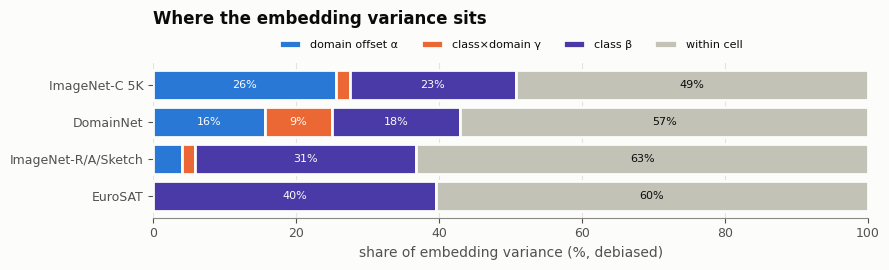

In [5]:
plots.variance_shares(DATASETS);

## 5. Oracle cells
Domain-averaged accuracy of every cell; `vs_zero_shot` and its 95% CI are relative to `txt_` (zero-shot).

In [6]:
for ds, s in S.items():
    print('==', LABEL[ds]); display(s.cells().round(2))

== ImageNet-C 5K


,cell,acc,vs_zero_shot,ci_lo,ci_hi
0,img_,19.37,-7.90,-8.53,-7.24
1,img_L,18.23,-9.04,-9.68,-8.36
2,img_A,21.34,-5.93,-6.58,-5.24
3,img_AL,20.23,-7.04,-7.67,-6.32
4,img_G,19.68,-7.59,-8.21,-6.91
5,img_GL,18.40,-8.87,-9.54,-8.20
6,img_AG,21.63,-5.64,-6.28,-4.94
7,img_AGL,20.26,-7.01,-7.64,-6.27
8,txt_,27.27,0.00,0.00,0.00
9,txt_L,26.46,-0.81,-1.04,-0.58


== DomainNet


,cell,acc,vs_zero_shot,ci_lo,ci_hi
0,img_,50.51,-4.86,-4.98,-4.75
1,img_L,50.47,-4.90,-5.03,-4.79
2,img_A,53.75,-1.62,-1.73,-1.52
3,img_AL,53.79,-1.58,-1.69,-1.47
4,img_G,55.62,0.25,0.12,0.38
5,img_GL,56.67,1.30,1.16,1.43
6,img_AG,58.14,2.76,2.63,2.89
7,img_AGL,59.13,3.75,3.61,3.88
8,txt_,55.37,0.00,0.00,0.00
9,txt_L,56.16,0.79,0.72,0.86


== ImageNet-R/A/Sketch


,cell,acc,vs_zero_shot,ci_lo,ci_hi
0,img_,50.46,4.12,3.64,4.56
1,img_L,55.98,9.64,9.17,10.08
2,img_A,52.68,6.34,5.85,6.77
3,img_AL,57.52,11.18,10.70,11.60
4,img_G,54.29,7.95,7.46,8.43
5,img_GL,59.46,13.12,12.62,13.60
6,img_AG,56.15,9.81,9.31,10.28
7,img_AGL,60.59,14.25,13.77,14.69
8,txt_,46.34,0.00,0.00,0.00
9,txt_L,58.90,12.56,12.22,12.91


== EuroSAT


,cell,acc,vs_zero_shot,ci_lo,ci_hi
0,img_,77.49,29.40,28.68,30.10
1,img_L,77.56,29.47,28.76,30.16
2,img_A,77.49,29.40,28.68,30.10
3,img_AL,77.56,29.47,28.76,30.16
4,img_G,77.49,29.40,28.68,30.10
5,img_GL,77.56,29.47,28.76,30.16
6,img_AG,77.49,29.40,28.68,30.10
7,img_AGL,77.56,29.47,28.76,30.16
8,txt_,48.09,0.00,0.00,0.00
9,txt_L,47.31,-0.77,-1.01,-0.52


## 6. Shapley attribution
Image world over {A, G, L}, text world over {A, L}, text-prototype gap P0 − T, and Ramen − NoAdapt (cached).

In [7]:
for ds, s in S.items():
    print('==', LABEL[ds]); display(s.shapley().round(2))

== ImageNet-C 5K


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (img),A,1.94,1.78,2.09,216.99
1,image (img),G,0.19,0.11,0.28,21.47
2,image (img),L,-1.24,-1.42,-1.05,-138.46
3,text,A,1.66,1.50,1.82,190.90
4,text,L,-0.79,-1.02,-0.58,-90.90
5,text -> image,prototype gap P0 - T,-7.90,-8.53,-7.24,NaN
6,cached,Ramen - NoAdapt,5.79,5.45,6.15,NaN


== DomainNet


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (img),A,2.87,2.82,2.93,33.32
1,image (img),G,5.25,5.15,5.34,60.91
2,image (img),L,0.50,0.45,0.55,5.77
3,text,A,0.92,0.88,0.97,53.18
4,text,L,0.81,0.75,0.88,46.82
5,text -> image,prototype gap P0 - T,-4.86,-4.98,-4.75,NaN
6,cached,Ramen - NoAdapt,1.43,1.36,1.49,NaN


== ImageNet-R/A/Sketch


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (img),A,1.68,1.51,1.86,16.61
1,image (img),G,3.46,3.19,3.72,34.14
2,image (img),L,4.99,4.81,5.17,49.24
3,text,A,-0.44,-0.59,-0.30,-3.54
4,text,L,13.01,12.67,13.34,103.54
5,text -> image,prototype gap P0 - T,4.12,3.64,4.56,NaN
6,cached,Ramen - NoAdapt,1.50,1.27,1.75,NaN


== EuroSAT


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (img),A,0.00,0.00,0.00,0.0
1,image (img),G,0.00,0.00,0.00,0.0
2,image (img),L,0.07,-0.06,0.20,100.0
3,text,A,0.00,0.00,0.00,-0.0
4,text,L,-0.77,-1.01,-0.52,100.0
5,text -> image,prototype gap P0 - T,29.40,28.68,30.10,NaN
6,cached,Ramen - NoAdapt,14.56,14.02,15.12,NaN


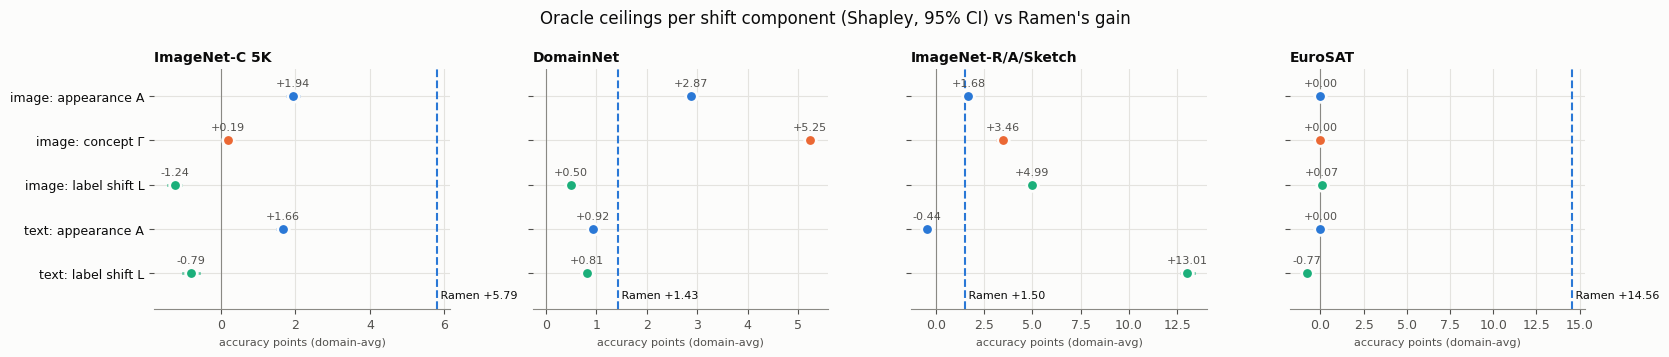

In [8]:
plots.shapley_vs_ramen(DATASETS);

## 7. Per domain
Image-world Shapley values per domain (point estimates) next to Ramen's per-domain gain.

In [9]:
for ds in ['ImageNetC5K', 'DomainNet', 'ImageNetVariants']:
    print('==', LABEL[ds]); display(S[ds].per_domain().round(2))

== ImageNet-C 5K


,domain,images,zero_shot,P0,phi_A,phi_G,phi_L,txt_phi_A,txt_phi_L,ramen_gain
0,gaussian_noise,5000,14.94,12.42,1.53,0.01,-0.88,1.94,-0.32,7.24
1,shot_noise,5000,16.94,13.90,2.27,-0.23,-1.26,2.41,-0.61,6.30
2,impulse_noise,5000,15.36,13.56,1.47,-0.05,-0.87,3.13,-0.51,8.28
3,defocus_blur,5000,25.64,20.60,1.78,-0.53,-1.56,0.99,-1.05,2.84
4,glass_blur,5000,16.90,13.92,1.21,0.28,-1.08,1.59,-0.83,7.30
5,motion_blur,5000,26.76,18.76,2.30,-0.31,-1.52,1.18,-0.84,6.06
6,zoom_blur,5000,24.54,16.74,1.91,-0.20,-1.25,0.89,-0.81,5.18
7,snow,5000,34.00,23.60,1.43,0.40,-1.08,2.29,-1.11,3.40
8,frost,5000,33.00,21.32,2.03,0.00,-1.05,2.24,-0.64,1.96
9,fog,5000,39.18,26.36,2.75,0.19,-1.77,1.27,-0.93,4.96


== DomainNet


,domain,images,zero_shot,P0,phi_A,phi_G,phi_L,txt_phi_A,txt_phi_L,ramen_gain
0,clipart,48833,68.27,62.00,1.95,5.08,1.25,0.14,0.91,1.08
1,infograph,53201,43.90,37.39,5.66,-0.24,0.44,1.79,1.37,1.08
2,painting,75759,64.60,58.22,3.77,2.08,0.62,1.08,1.38,1.12
3,quickdraw,172500,13.31,13.45,4.12,20.50,-0.05,2.48,-0.01,4.21
4,real,175327,82.12,75.77,1.07,2.29,-0.10,-0.23,0.19,0.15
5,sketch,70386,60.04,56.26,0.65,1.76,0.82,0.29,1.05,0.91


== ImageNet-R/A/Sketch


,domain,images,zero_shot,P0,phi_A,phi_G,phi_L,txt_phi_A,txt_phi_L,ramen_gain
0,rendition,30000,59.97,59.19,1.39,-0.61,12.14,-0.42,18.52,2.43
1,adversarial,7500,30.67,36.68,3.34,8.92,3.11,-1.45,20.94,0.76
2,sketch,50889,48.39,55.51,0.32,2.06,-0.29,0.53,-0.44,1.33


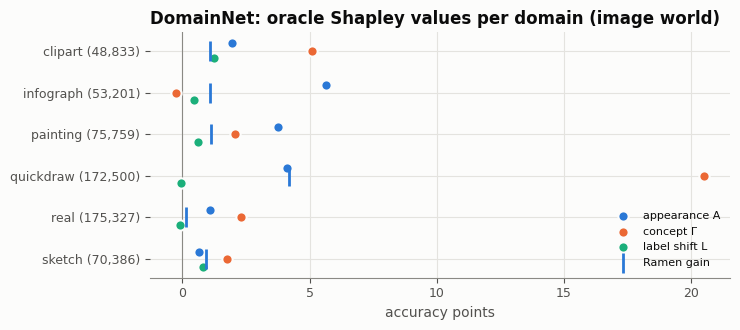

In [10]:
plots.per_domain_shapley('DomainNet');

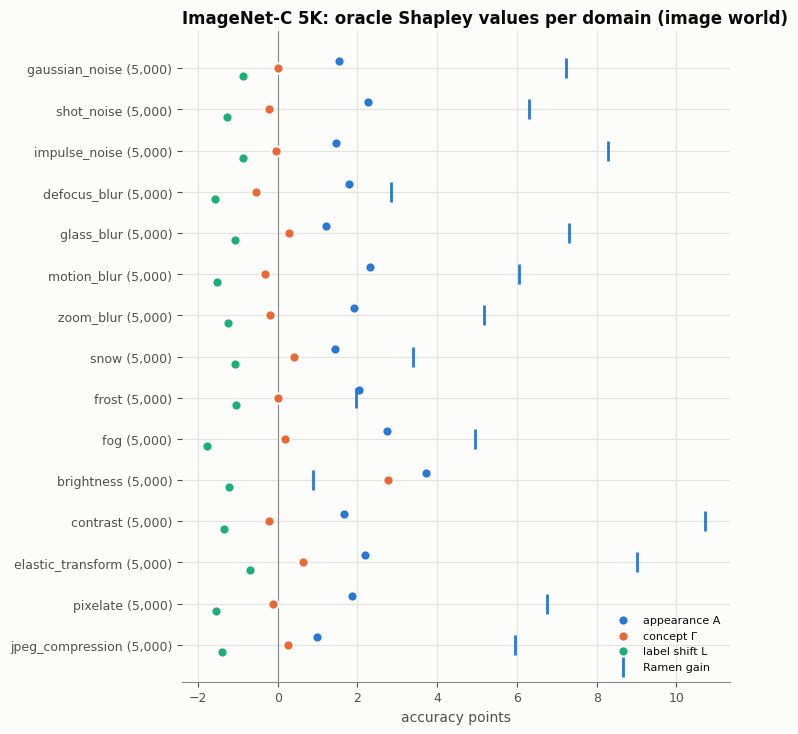

In [11]:
plots.per_domain_shapley('ImageNetC5K');

## 8. Robustness and controls
Gains over P0 (points): true domains vs **random domains** (control; relative to the random-domain fit P0 `rnd_`), unshrunk γ, and the 2-fold cross-fit.

In [12]:
rows = []
for ds, s in S.items():
    if s.e.meta['domain_names'] and len(s.e.meta['domain_names']) > 1:
        a = s.acc
        rows.append(dict(dataset=LABEL[ds], P0=a['img_'], A=a['img_A'] - a['img_'], G=a['img_G'] - a['img_'],
                         AG=a['img_AG'] - a['img_'], rnd_P0=a['rnd_'], rnd_A=a['rnd_A'] - a['rnd_'],
                         rnd_G=a['rnd_G'] - a['rnd_'], rnd_AG=a['rnd_AG'] - a['rnd_'],
                         G_unshrunk=a['img_G_n0'] - a['img_'],
                         cf_P0=a['cf_'], cf_AG=a['cf_AG'] - a['cf_'], cf_AGL=a['cf_AGL'] - a['cf_']))
pd.DataFrame(rows).round(2)

,dataset,P0,A,G,AG,rnd_P0,rnd_A,rnd_G,rnd_AG,G_unshrunk,cf_P0,cf_AG,cf_AGL
0,ImageNet-C 5K,19.37,1.98,0.31,2.27,19.36,0.02,0.0,0.02,-2.67,15.20,1.63,0.05
1,DomainNet,50.51,3.24,5.11,7.62,49.43,0.00,0.0,0.00,5.00,50.45,7.57,8.37
2,ImageNet-R/A/Sketch,50.46,2.22,3.83,5.69,49.73,0.02,0.0,0.02,2.59,49.72,4.91,8.99


In [13]:
for ds, s in S.items():
    print('==', LABEL[ds], '(cross-fit)'); display(s.shapley(prefix='cf').round(2))

== ImageNet-C 5K (cross-fit)


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (cf),A,1.51,1.36,1.66,3062.16
1,image (cf),G,0.00,0.00,0.00,0.00
2,image (cf),L,-1.46,-1.68,-1.25,-2962.16


== DomainNet (cross-fit)


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (cf),A,2.89,2.84,2.95,34.56
1,image (cf),G,5.08,4.98,5.17,60.64
2,image (cf),L,0.40,0.35,0.45,4.79


== ImageNet-R/A/Sketch (cross-fit)


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (cf),A,1.67,1.50,1.83,18.62
1,image (cf),G,2.77,2.54,2.99,30.85
2,image (cf),L,4.54,4.36,4.74,50.53


== EuroSAT (cross-fit)


,world,component,phi,ci_lo,ci_hi,share_pct
0,image (cf),A,0.00,0.00,0.00,-0.0
1,image (cf),G,0.00,0.00,0.00,-0.0
2,image (cf),L,-0.02,-0.16,0.12,100.0


## 9. Pre-registered decision

In [14]:
pd.DataFrame([s.decision() for s in S.values()])

,dataset,dominant,phi_A_plus_G,ramen_gain,domain_aware_alive
0,ImageNetC5K,[A],2.13,5.79,False
1,DomainNet,[G],8.12,1.43,True
2,ImageNetVariants,[none],5.14,1.50,True
3,EuroSAT,[none],0.00,14.56,False


In [15]:
overview(DATASETS).round(2)

,dataset,zero_shot,ramen_gain,floor,P0,full_oracle,img_phi_A,img_phi_G,img_phi_L,txt_phi_A,txt_phi_L,gamma_reliability,n0,dominant
0,ImageNet-C 5K,27.27,5.79,0.54,19.37,20.26,1.94,0.19,-1.24,1.66,-0.79,0.46,3.14e+01,A
1,DomainNet,55.37,1.43,0.11,50.51,59.13,2.87,5.25,0.50,0.92,0.81,0.94,6.11e+00,G
2,ImageNet-R/A/Sketch,46.34,1.50,0.48,50.46,60.59,1.68,3.46,4.99,-0.44,13.01,0.81,3.40e+01,none
3,EuroSAT,48.09,14.56,1.51,77.49,77.56,0.00,0.00,0.07,0.00,-0.77,NaN,1.49e+31,none


## 10. Interpretation

**Predictions (pre-registered).** ImageNet-C → A: **confirmed** (φ_A +1.94, CI [1.78, 2.09]; Γ +0.19; L −1.24, so the
"share" numbers are meaningless there and A is simply the only sizeable positive component). DomainNet → Γ: **confirmed**
(φ_Γ +5.25 of +8.62, 61%; quickdraw alone +20.5). ImageNet-R/A/Sketch → L: **narrowly fails** (L is 49.2% < 50%, Γ 34%,
so no single component dominates by the rule). EuroSAT A = Γ = 0: **confirmed** (identical predictions, 100.00%).

**Decision rule (φ_A + φ_Γ vs Ramen's gain).** DomainNet 8.12 vs 1.43 and R/A/Sketch 5.14 vs 1.50: **domain-aware direction
alive**. ImageNet-C 2.13 vs 5.79 and EuroSAT 0 vs 14.56: **not alive**.

**Read against zero-shot, not only P0.** Image-world gains start from pooled image prototypes, which are *below* zero-shot on
ImageNet-C (−7.90: ~4 other photos per class after leaving the photo out) and DomainNet (−4.86). Per-domain class means
(`img_AG`) vs zero-shot: DomainNet +2.76 (+3.75 with L), R/A/Sketch +9.81 (+14.25), ImageNet-C −5.64. So on DomainNet,
concept-aware prototypes are worth about 2× Ramen's gain over zero-shot; on ImageNet-C they are worse than the text prompt.

**What the controls say.** Random domain labels give +0.00 to +0.02 over their own P0 on all three multi-domain datasets, so
A and Γ gains are domain effects. The 2-fold cross-fit reproduces the Shapley values (DomainNet Γ 5.08, A 2.89; R/A/Sketch
Γ 2.77); γ split-half reliability is high on DomainNet (0.94) and R/A/Sketch (0.81), moderate on ImageNet-C (0.46).

**Mechanistic reading.** On corruptions, the domain change is mostly a common offset (α 26% of embedding variance, γ 2%, F 1.17),
and Ramen's +5.79 is far above every mean-based ceiling: its gain must come from something a mean shift of the frozen feature
cannot do (re-encoding the image with adapted norm layers; consistent with, not proven by, this result). On DomainNet the
class-specific part is real (γ 9% of variance, F 58) and concentrated in quickdraw, where Ramen's sink problems also live.

**Caveats.** Oracle ceilings (true labels and domains); seed-independent; one feature extractor per dataset; means only
(Γ is a lower bound on concept shift); L in the text world assumes CLIP's implicit prior is uniform, and it hurts on
ImageNet-C / EuroSAT.

**Next.** Step 2 screen on DomainNet and R/A/Sketch: can label-free domain inference (style statistics) plus label-free
per-domain prototypes recover a useful fraction of `img_AG − txt_` (+2.76 DomainNet)? Zero-shot pseudo-labels already failed as
a CE target, so the per-domain prototype estimate is the hard part, not the domain id (text-world A with domain means
`txt_Ad` ≈ the class-adjusted oracle `txt_A`).


## 11. Glossary

| term | meaning |
|---|---|
| oracle | uses true labels and/or domains; an upper bound, not a method |
| appearance (A) | $\alpha_d$: the part of the domain change shared by all classes (a translation of the whole domain in embedding space) |
| concept (Γ) | $\gamma_{c,d}$: the class-specific part of the domain change (class $c$ moves differently in domain $d$) |
| label shift (L) | different class frequencies $\pi_{c\mid d}$ per domain |
| P0 | pooled image prototypes (class means over all domains): the image-world baseline |
| text-prototype gap | P0 − zero-shot: how much better image class means are than CLIP's text embeddings, with no shift fixed |
| Shapley value | average gain from adding one fix, over all orders of adding the fixes; the values sum to (all fixes − none) |
| leave-one-out / group | image $i$'s own class statistics exclude $i$ (and its corrupted copies on ImageNet-C) so it cannot vote for itself |
| shrinkage $n_0$ | γ is multiplied by $n/(n+n_0)$: cells with few images are pulled toward "no interaction" |
| cross-fit | statistics estimated on one half of the images, accuracy measured on the other |
| random-domain control | same fits with domain labels shuffled; any gain there is not a domain effect |
| domain-averaged accuracy | mean over domains of each domain's accuracy (the project's headline convention) |
| noise floor | 2 × (max − min) of Ramen's accuracy over seeds 0–4 |
